In [6]:
import geemap
import ee

#ee.Authenticate(force=True)
ee.Initialize(project='ee-sbouchiba')


In [7]:
## Import cities footprint
import geopandas as gpd
import json

city_names = ['basel', 'bern', 'geneva', 'lausanne', 'lugano', 'zurich']
train_city = 'geneva'
relabel='False'
#test_city = 'lausanne'

allcity_roi_path = './input/footprints/study_areas.geojson'

allcity_roi_gpd = gpd.read_file(allcity_roi_path)
allcity_roi_gpd = allcity_roi_gpd.to_crs("EPSG:4326") # convert projected CRS into WGS84 longitude/latitude.

geom = {
    "geneva":   allcity_roi_gpd.geometry.iloc[0],
    "lausanne": allcity_roi_gpd.geometry.iloc[1],
    "bern":     allcity_roi_gpd.geometry.iloc[2],
    "basel":    allcity_roi_gpd.geometry.iloc[3],
    "zurich":   allcity_roi_gpd.geometry.iloc[4],
    "lugano":   allcity_roi_gpd.geometry.iloc[5],
    "allcity":  allcity_roi_gpd.union_all(),
}

roi = ee.Geometry(geom[train_city].__geo_interface__)
roi_fc = ee.FeatureCollection([ee.Feature(roi)])


## #Import train/test datasets

In [8]:

import geopandas as gpd
import pandas as pd


## Training samples
if train_city=='allcity':
    centroid_gdfs = []
    polygon_gdfs  = []
    for city in city_names:
        centroid_gdf = gpd.read_file(
            f"./input/samples/{city}_2022_training_centroids.geojson"
        )
        polygon_gdf = gpd.read_file(
            f"./input/samples/{city}_2022_training_polygons.geojson"
        )
    
        # Optional: keep track of origin city
        centroid_gdf["city"] = city
        polygon_gdf["city"] = city
    
        centroid_gdfs.append(centroid_gdf)
        polygon_gdfs.append(polygon_gdf)
    
    # Merge all cities
    train_centroids_gdf = gpd.GeoDataFrame(
        pd.concat(centroid_gdfs, ignore_index=True),
        crs=centroid_gdfs[0].crs
    )
    
    train_polygons_gdf = gpd.GeoDataFrame(
        pd.concat(polygon_gdfs, ignore_index=True),
        crs=polygon_gdfs[0].crs
    )

else:
    if train_city == 'geneva' and relabel=='True':
        print("oh yeaaaah")
        train_centroids_gdf = gpd.read_file(f'./input/samples/geneva_2022_training_centroids_relabelled_v1.geojson')
        #train_centroids_gdf = gpd.read_file(f'./input/samples/geneva_2022_training_centroids.geojson')
        print(train_centroids_gdf[train_centroids_gdf['id_num']==178])
    else:
        train_centroids_gdf = gpd.read_file(f'./input/samples/{train_city}_2022_training_centroids.geojson')

        
    train_polygons_gdf = gpd.read_file(f'./input/samples/{train_city}_2022_training_polygons.geojson')
    train_centroids_gdf['city'] = train_city
    train_polygons_gdf['city'] = train_city

train_centroids = geemap.geopandas_to_ee(train_centroids_gdf)
train_polygons  = geemap.geopandas_to_ee(train_polygons_gdf)


In [9]:
### Import test 
import numpy as np
import pandas as pd

test_city = 'geneva'

if test_city == 'geneva':
    #test_centroids_gdf = gpd.read_file(f"./input/samples/geneva_2022_training_centroids_relabelled_new_points_v1.geojson")
    test_centroids_gdf = gpd.read_file(f"./input/samples/geneva_2022_testing_centroids.geojson")
    test_polygons_gdf = gpd.read_file(f"./input/samples/geneva_2022_testing_polygons.geojson")
else:
    test_centroids_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_centroids.geojson")
    test_polygons_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_polygons.geojson")


test_centroids  = geemap.geopandas_to_ee(test_centroids_gdf)
test_polygons   = geemap.geopandas_to_ee(test_polygons_gdf)


In [10]:
train_centroids_gdf

,fid,roi_id,macroclass_id,class_id,city,LCZ_class,point_id,id_num,geometry
0,756,s20231219_155139133834_585,2,2,geneva,1,geneva_0,0,POINT (6.13859 46.19989)
1,757,s20231219_155140503568_983,2,3,geneva,1,geneva_1,1,POINT (6.1591 46.20351)
2,758,s20231219_155141953736_803,2,5,geneva,1,geneva_2,2,POINT (6.14748 46.2142)
3,759,s20231219_155143315377_477,2,6,geneva,1,geneva_3,3,POINT (6.13088 46.21226)
4,760,s20231219_155144700800_99,2,10,geneva,1,geneva_4,4,POINT (6.134 46.19854)
...,...,...,...,...,...,...,...,...,...
370,1218,s20231219_160846052972_648,17,59,geneva,8,geneva_370,370,POINT (6.17137 46.18214)
371,1219,s20231219_160847440661_217,17,60,geneva,8,geneva_371,371,POINT (6.14002 46.19204)
372,1220,s20231219_160848812777_905,17,61,geneva,8,geneva_372,372,POINT (6.10485 46.19874)
373,1221,s20231219_160850180061_817,17,62,geneva,8,geneva_373,373,POINT (6.08681 46.20981)


### Import DSM (digital surface model)/MNS
* Used model: **swissSURFACED**, use LiDAR and photogrammetry, naked topography (no trees, building etc.)
* Source: https:https://www.swisstopo.admin.ch/fr/modele-altimetrique-swisssurface3d
* Extracted files corresponding to each city ROI (`4a_extract_surface_files.py`)
* Built surface GeoTIFF: extracted ground and building altitude to get building height.
* Put the GeoTIFF in GEE assets (`/topo/swissSURFACE3D/geotiff/{city}_surface.tiff`):
    * Go to https://code.earthengine.google.com/
    * Select left table "Assets"
    * Add local `.tif` files in EE project.

In [11]:
topo   = ee.Image("projects/ee-sbouchiba/assets/geneva_surface")
# If you want all 3 bands with nice names:
topo = topo.select(['b1','b2','b3']).rename(['ground_elev','building_elev','building_height'])
height = topo.select('building_height')
ground_elev = topo.select('ground_elev')
building_elev = topo.select('building_elev')

# Replace nodata (-9999) with 0 — means "no building here"


# unmask fills ALL nodata (including areas outside the tiff extent) with 0
height = height.where(height.eq(-9999), 0)
height = height.unmask(0)
ground_elev = ground_elev.where(ground_elev.eq(-9999), 0)
ground_elev = ground_elev.unmask(0)
building_elev = building_elev.where(building_elev.eq(-9999), 0)
building_elev = building_elev.unmask(0)
# Optional: also clip any floating point noise to 0
height = height.max(ee.Image(0))

print(topo.bandNames().getInfo())
print(topo.projection().getInfo())
print(topo.geometry().bounds().getInfo())

['ground_elev', 'building_elev', 'building_height']
{'type': 'Projection', 'crs': 'EPSG:2056', 'transform': [10, 0, 2485000, 0, -10, 1137000]}
{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[5.943883601763331, 46.12261854692668], [6.3131086128424165, 46.12261854692668], [6.3131086128424165, 46.37875882984807], [5.943883601763331, 46.37875882984807], [5.943883601763331, 46.12261854692668]]]}


In [12]:
height_check = height.sampleRegions(
    collection=test_centroids,
    properties=['LCZ_class'],
    scale=10
)

height_df = pd.DataFrame(height_check.getInfo()['features'])
height_df = pd.json_normalize(height_df['properties'])

'''
print(height_df.groupby('LCZ_class')['building_height'].describe())
print("\nHow many zeros per class:")
print(height_df.groupby('LCZ_class')['building_height'].apply(lambda x: (x==0).sum()))
print("\nHow many nulls per class:")
print(height_df.groupby('LCZ_class')['building_height'].apply(lambda x: x.isna().sum()))
'''

'\nprint(height_df.groupby(\'LCZ_class\')[\'building_height\'].describe())\nprint("\nHow many zeros per class:")\nprint(height_df.groupby(\'LCZ_class\')[\'building_height\'].apply(lambda x: (x==0).sum()))\nprint("\nHow many nulls per class:")\nprint(height_df.groupby(\'LCZ_class\')[\'building_height\'].apply(lambda x: x.isna().sum()))\n'

In [13]:
#### Simple geemap visualizer

In [14]:


Map = geemap.Map()
Map.centerObject(roi, 12)

# Add the height layer
Map.addLayer(
    height.updateMask(height.gt(0)),  # only show where buildings exist
    {'min': 0, 'max': 40, 'palette': ['yellow', 'orange', 'red', 'darkred']},
    'Building Height'
)

# Add test and train points colored by LCZ class
#Map.addLayer(test_centroids, {'color': 'blue'}, 'Test points')
Map.addLayer(train_centroids, {'color': 'green'}, 'Train points')

#Map

##### Per-regions heatmaps

In [15]:
import rasterio
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import numpy as np
import geopandas as gpd

out_dir = "./images/"
# Files
height_tiff_path = "./topo/swissSURFACE3D/geotiff/geneva_surface.tif"
train_points_path = out_dir + "training_points_v3.geojson"
test_points_path = f"./input/samples/geneva_2022_testing_centroids.geojson"

# Read building height band
with rasterio.open(height_tiff_path) as src:
    height_band = src.read(3, masked=True).astype(np.float32)
    height_band = height_band.filled(np.nan)
    bounds = src.bounds
    tiff_crs = src.crs  # EPSG:2056

from rasterio.warp import calculate_default_transform, reproject, Resampling

height_tiff_4326 = "./topo/swissSURFACE3D/geotiff/geneva_height_4326.tif"

with rasterio.open(height_tiff_path) as src:
    transform, width, height_ = calculate_default_transform(
        src.crs, 'EPSG:4326', src.width, src.height, *src.bounds
    )
    profile = src.profile.copy()
    profile.update(
        crs='EPSG:4326',
        transform=transform,
        width=width,
        height=height_,
    )
    with rasterio.open(height_tiff_4326, 'w', **profile) as dst:
        reproject(
            source=rasterio.band(src, 3),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs='EPSG:4326',
            resampling=Resampling.bilinear,
            src_nodata=-9999,
            dst_nodata=-9999,
        )

# Now read the reprojected file
with rasterio.open(height_tiff_4326) as src:
    height_band = src.read(1, masked=True).astype(np.float32)
    height_band = height_band.filled(np.nan)
    bounds = src.bounds

print(bounds)
print(height_band.shape)
print(f"min: {np.nanmin(height_band):.2f}, max: {np.nanmax(height_band):.2f}")

# Mask nodata
#height_band[height_band == -9999] = np.nan


# Class colors and names

palette = [
    "#7A2A12",  # Compact MR
    "#DE6321",  # Open MR
    "#EAC89E",  # Open LR
    "#CFC9AE",  # Large LR
    "#5A772C",  # Dense Trees
    "#A2C766",  # Low plants
    "#4A442B",  # Bare Rock/Paved
    "#89C9E8"   # Water
]


class_colors = {i+1: palette[i] for i in range(8)}
class_names = [
    "Compact MR", "Open MR", "Open LR", "Large LR",
    "Dense Trees", "Low Plants", "Bare/Paved", "Water"
]

# Height colormap: yellow -> orange -> red -> darkred
height_cmap = mcolors.LinearSegmentedColormap.from_list(
    "b3", ["#FFFF00", "#FFA500", "#FF0000", "#8B0000"]
)





BoundingBox(left=5.9439485174811555, bottom=46.122682590963194, right=6.313011576843262, top=46.37871447612286)
(2281, 3288)
min: -4.03, max: 95.04


### Interactive map with training points + classes

In [16]:
### Violin plots

In [17]:
def sample_heights(fc, height_img, scale=10):
    fc_check = height_img.sampleRegions(
        collection=fc,
        properties=['LCZ_class', 'id_num'],
        scale=scale
    )
    df = pd.DataFrame(fc_check.getInfo()['features'])
    df = pd.json_normalize(df['properties'])
    return df

df_train = sample_heights(train_centroids, height)
df_test  = sample_heights(test_centroids,  height)

In [18]:
df_train['LCZ_class']

0      1
1      1
2      1
3      1
4      1
      ..
351    8
352    8
353    8
354    8
355    8
Name: LCZ_class, Length: 356, dtype: int64

In [19]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

urban_classes = {1: 'Compact MR', 2: 'Open MR', 3: 'Open LR', 4: 'Large LR'}
urban_palette = {1: '#7A2A12', 2: '#DE6321', 3: '#EAC89E', 4: '#CFC9AE'}

def prep_urban(df):
    d = df[df['LCZ_class'].isin(urban_classes.keys())].copy()
    d = d.dropna(subset=['building_height'])
    d = d[d['building_height'] > 0]
    return d

def plot_height_violin(df, marker, title_suffix, out_path):
    labels = list(urban_classes.values())
    colors = list(urban_palette.values())
    data_by_class = [df[df['LCZ_class'] == cls]['building_height'].values for cls in urban_classes.keys()]
    ids_by_class   = [df[df['LCZ_class'] == cls]['id_num'].values for cls in urban_classes.keys()]

    fig, ax = plt.subplots(figsize=(9, 6))
    parts = ax.violinplot(data_by_class, positions=range(len(labels)), showmedians=True, showextrema=True)

    for pc, color in zip(parts['bodies'], colors):
        pc.set_facecolor(color); pc.set_edgecolor('black'); pc.set_alpha(0.8)
    for partname in ('cmedians', 'cmins', 'cmaxes', 'cbars'):
        parts[partname].set_edgecolor('black'); parts[partname].set_linewidth(1.2)

    for i, (data, ids, color) in enumerate(zip(data_by_class, ids_by_class, colors)):
        jitter = np.random.uniform(-0.08, 0.08, size=len(data))
        x = np.full_like(data, i, dtype=float) + jitter
        ax.scatter(x, data, marker=marker, color=color, edgecolor='black',
                   linewidth=0.5, s=40, alpha=0.75, zorder=3)
        # ID label next to each point
        for xi, yi, id_val in zip(x, data, ids):
            ax.annotate(str(int(id_val)), (xi, yi), xytext=(4, 0),
                        textcoords='offset points', fontsize=6, alpha=0.85, zorder=4)

    for i, data in enumerate(data_by_class):
        ax.text(i, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 50,
                f'n={len(data)}\nmed={np.median(data):.1f}m',
                ha='center', va='bottom', fontsize=9)

    ax.set_xticks(range(len(labels)))
    ax.set_ylim(0, 35)
    ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylabel('Building height [m]', fontsize=11)
    ax.set_xlabel('LCZ class', fontsize=11)
    #ax.set_title(f'Building height distribution by urban LCZ class ({title_suffix})', fontsize=12)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    patches = [mpatches.Patch(facecolor=colors[i], edgecolor='black', label=labels[i]) for i in range(len(labels))]
    ax.legend(handles=patches, loc='best')
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()



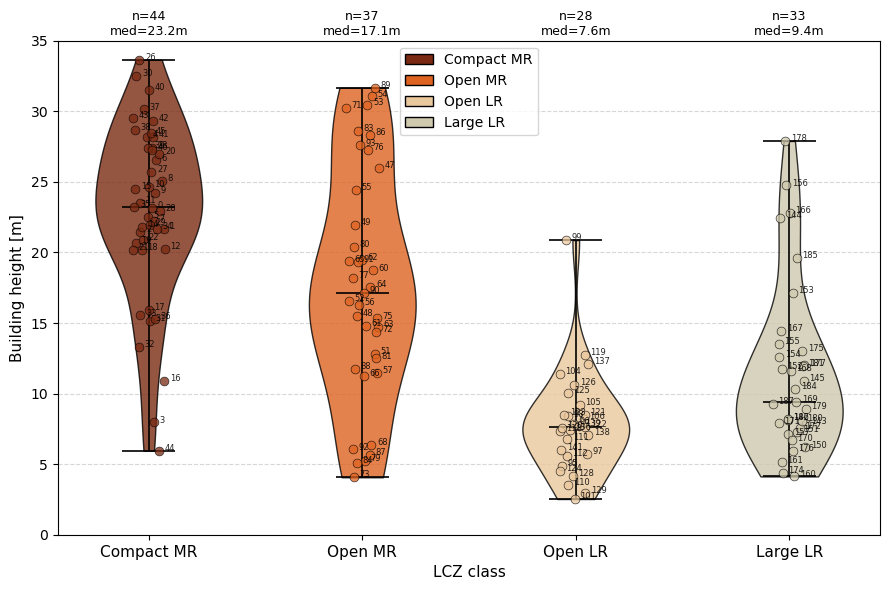

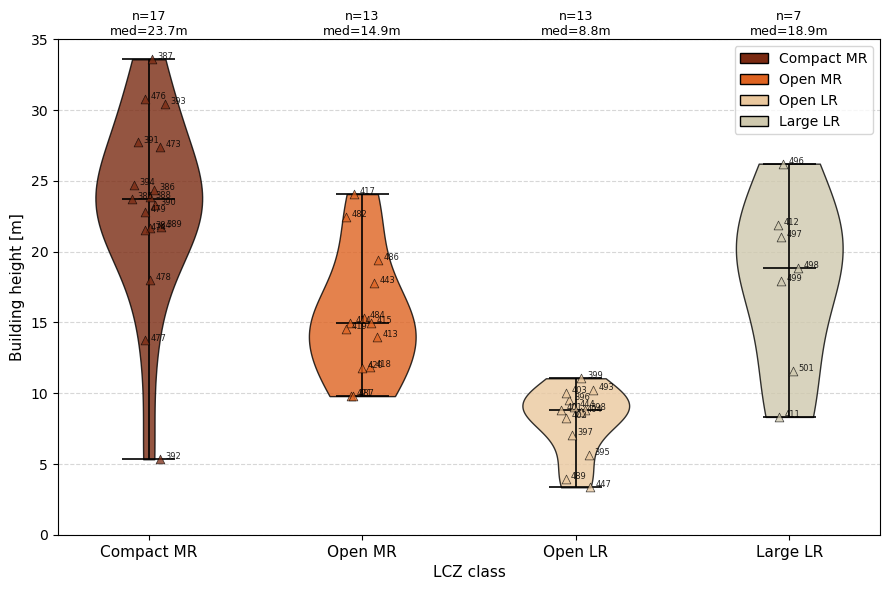

In [20]:

df_train_urban = prep_urban(df_train)
df_test_urban  = prep_urban(df_test)

out_dir='./images/'
plot_height_violin(df_train_urban, marker='o', title_suffix='train',
                    out_path=out_dir + "building_height_violin_urban_lcz_train_og.png")
plot_height_violin(df_test_urban,  marker='^', title_suffix='test',
                    out_path=out_dir + "building_height_violin_urban_lcz_test_og.png")

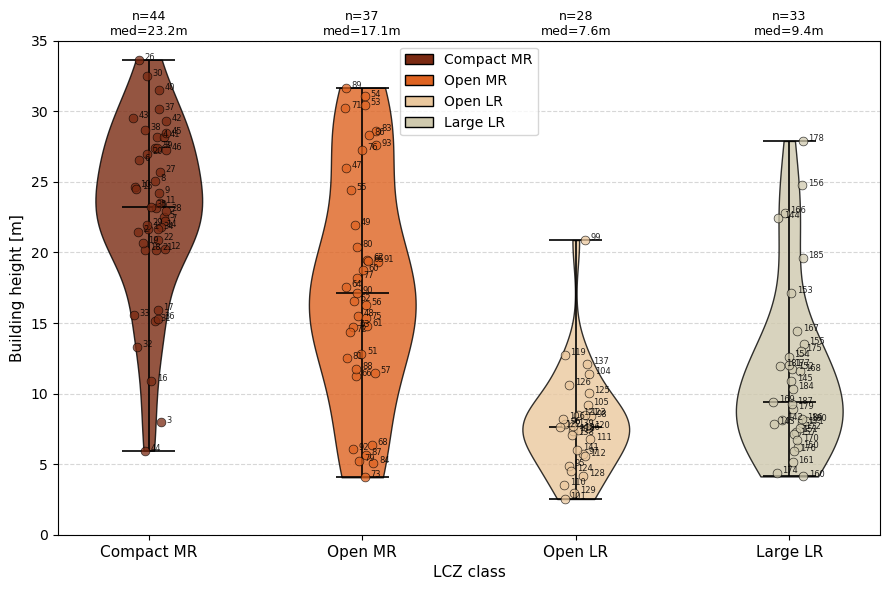

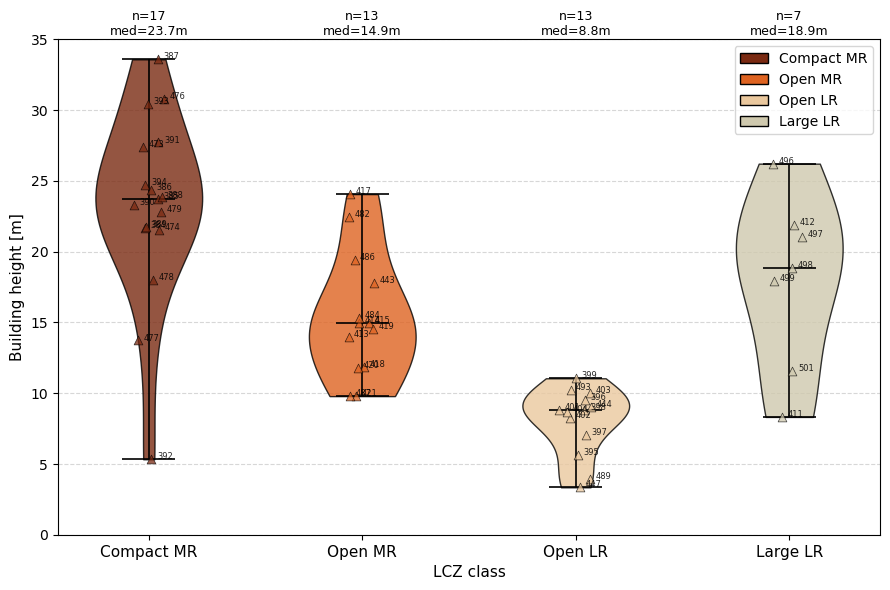

In [21]:
## No relabelled


df_train = sample_heights(train_centroids, height)
df_test  = sample_heights(test_centroids,  height)

df_train_urban = prep_urban(df_train)
df_test_urban  = prep_urban(df_test)

out_dir='./images/'
plot_height_violin(df_train_urban, marker='o', title_suffix='train',
                    out_path=out_dir + "building_height_violin_urban_lcz_train_relabelled.png")
plot_height_violin(df_test_urban,  marker='^', title_suffix='test',
                    out_path=out_dir + "building_height_violin_urban_lcz_test_relabelled.png")

### Interactive map

Tall Open/Large LR points: 23 train, 10 test
IDs: [99, 104, 119, 126, 137, 143, 144, 145, 152, 153, 154, 155, 156, 166, 167, 168, 169, 175, 177, 178, 181, 184, 185, 399, 401, 412, 493, 495, 496, 497, 498, 499, 501]
Short Compact/Open MR points: 14 train, 5 test
IDs: [3, 32, 44, 51, 57, 66, 72, 73, 79, 81, 84, 87, 88, 92, 392, 418, 420, 421, 487]



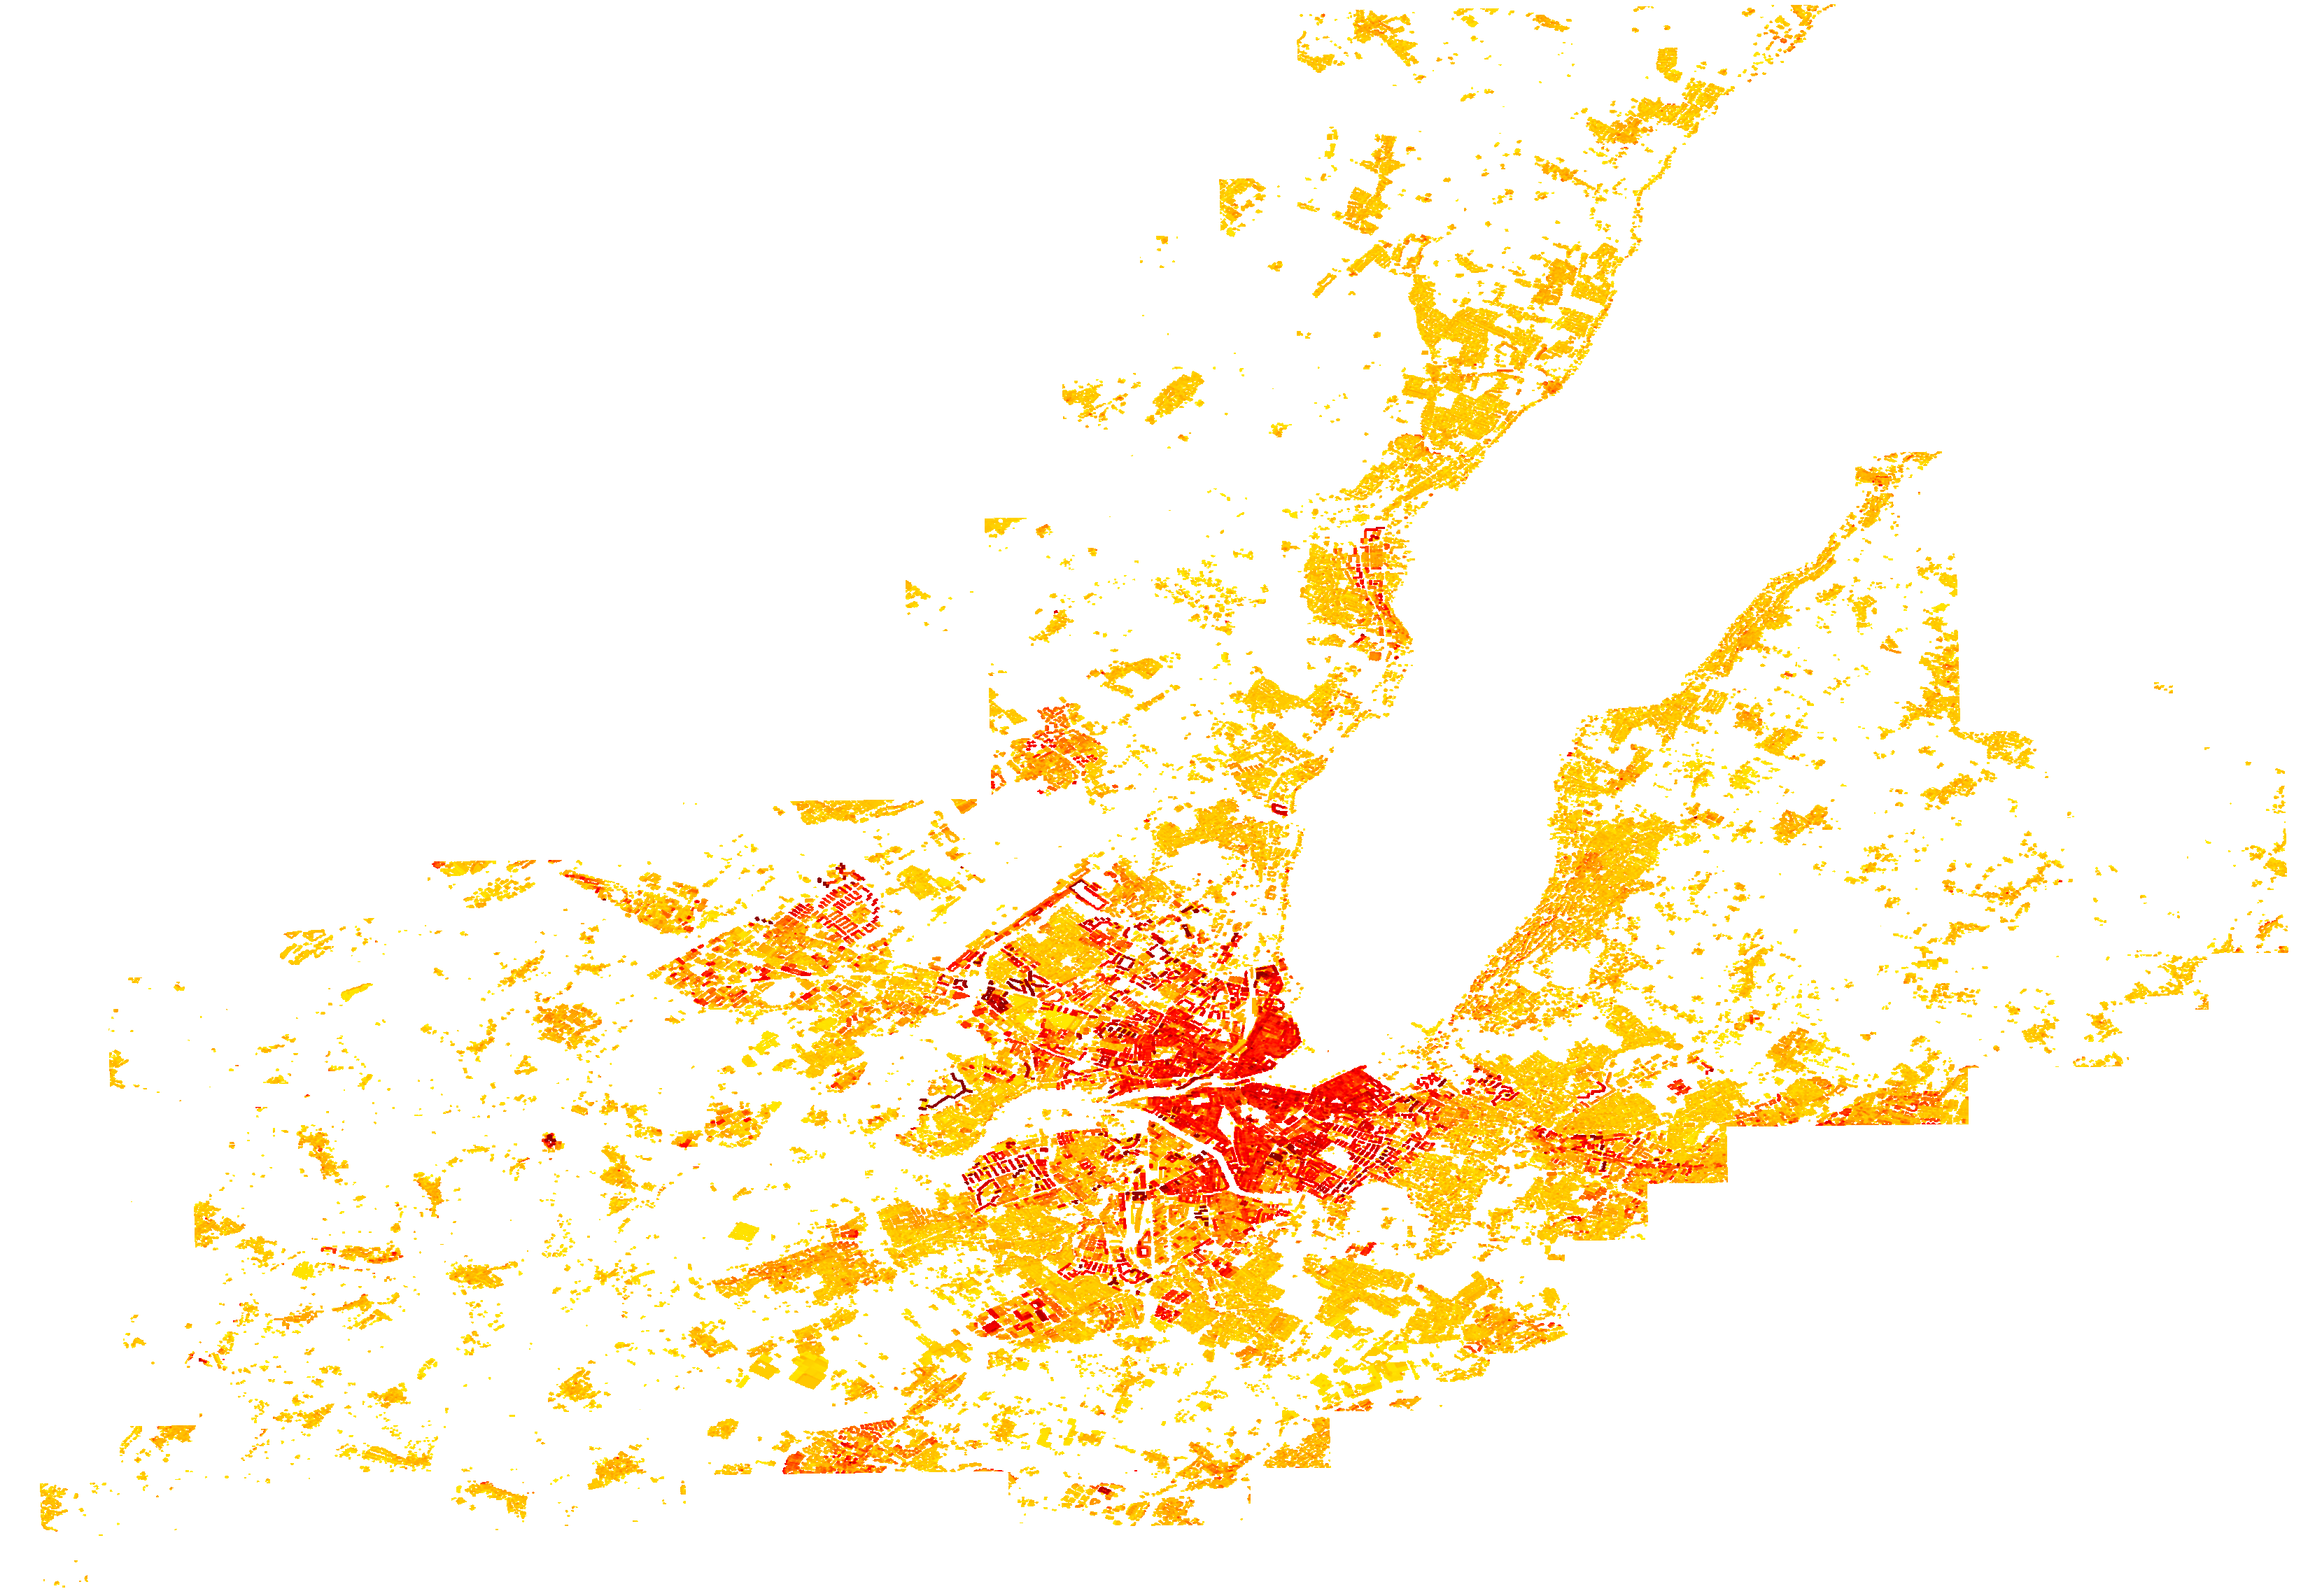

In [22]:
import folium
import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from folium.plugins import Fullscreen

class_labels = {1:'Compact MR', 2:'Open MR', 3:'Open LR', 4:'Large LR',
                5:'Dense Trees', 6:'Low plants', 7:'Bare/Paved', 8:'Water'}

class_palette = {
    1: '#7A2A12', 2: '#DE6321', 3: '#EAC89E', 4: '#CFC9AE',
    5: '#5A772C', 6: '#A2C766', 7: '#4A442B', 8: '#89C9E8'
}

# --------------------------------------------------
# SAMPLE BUILDING HEIGHT AT EACH POINT
# --------------------------------------------------
def sample_height_at_points(gdf, raster_path):
    with rasterio.open(raster_path) as src:
        coords = list(zip(gdf.geometry.x, gdf.geometry.y))
        values = [v[0] for v in src.sample(coords)]
        nodata = src.nodata
    heights = [np.nan if (nodata is not None and v == nodata) else v for v in values]
    gdf = gdf.copy()
    gdf['building_height'] = heights
    return gdf

train_centroids_gdf = sample_height_at_points(train_centroids_gdf, height_tiff_4326)
test_centroids_gdf  = sample_height_at_points(test_centroids_gdf,  height_tiff_4326)

def height_str(h):
    return f"{h:.1f} m" if pd.notna(h) else "no data"

# --------------------------------------------------
# BUILDING HEIGHT RASTER → RGBA IMAGE OVERLAY
# --------------------------------------------------
height_cmap = mcolors.LinearSegmentedColormap.from_list(
    "building_height", ["yellow", "orange", "red", "darkred"]
)
norm = mcolors.Normalize(vmin=0, vmax=40)

with rasterio.open(height_tiff_4326) as src:
    height_band = src.read(1, masked=True).astype(np.float32)
    height_band = height_band.filled(np.nan)
    b = src.bounds

rgba = height_cmap(norm(height_band))
no_building = np.isnan(height_band) | (height_band <= 0)
rgba[no_building, 3] = 0
rgba_uint8 = (rgba * 255).astype(np.uint8)

# --------------------------------------------------
# BUILD MAP
# --------------------------------------------------
center = [(b.bottom + b.top) / 2, (b.left + b.right) / 2]
m = folium.Map(location=center, zoom_start=15, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Satellite", opacity=0.7
).add_to(m)
folium.TileLayer('CartoDB positron', name='CartoDB Positron').add_to(m)

# --- Building height image overlay ---
height_layer = folium.FeatureGroup(name='Building height', show=True)
folium.raster_layers.ImageOverlay(
    image=rgba_uint8,
    bounds=[[b.bottom, b.left], [b.top, b.right]],
    opacity=0.7,
    zindex=1,
).add_to(height_layer)
height_layer.add_to(m)

# --- Training polygons ---
train_poly_layer = folium.FeatureGroup(name='Training polygons', show=False)
for _, row in train_polygons_gdf.iterrows():
    lcz = int(row['LCZ_class'])
    color = class_palette.get(lcz, '#888888')
    folium.GeoJson(
        row['geometry'].__geo_interface__,
        style_function=lambda f, c=color: {
            'fillColor': c, 'color': c,
            'weight': 1, 'fillOpacity': 0.25, 'opacity': 0.6
        },
        tooltip=folium.Tooltip(
            f"<b>Training polygon</b><br>Class: {class_labels[lcz]}", sticky=True
        )
    ).add_to(train_poly_layer)
train_poly_layer.add_to(m)

# --- Per-class layers (train circles + test triangles) ---
class_layers = {cls: folium.FeatureGroup(name=f"{cls}: {label}", show=True)
                 for cls, label in class_labels.items()}

for _, row in train_centroids_gdf.iterrows():
    lcz = int(row['LCZ_class'])
    color = class_palette.get(lcz, '#888888')
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=6, color='black', weight=0.7,
        fill=True, fill_color=color, fill_opacity=0.9,
        tooltip=folium.Tooltip(
            f"<b>Training point (ID {int(row.id_num)})</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"Building height: {height_str(row.building_height)}",
            sticky=True
        )
    ).add_to(class_layers[lcz])

for _, row in test_centroids_gdf.iterrows():
    lcz = int(row['LCZ_class'])
    color = class_palette.get(lcz, '#888888')
    folium.RegularPolygonMarker(
        location=[row.geometry.y, row.geometry.x],
        number_of_sides=3, radius=6,
        color='black', weight=0.7,
        fill=True, fill_color=color, fill_opacity=0.9,
        tooltip=folium.Tooltip(
            f"<b>Test point (ID {int(row.id_num)})</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"Building height: {height_str(row.building_height)}",
            sticky=True
        )
    ).add_to(class_layers[lcz])


# --- Filtered layer: tall Open LR / Large LR points (train + test) ---
tall_lr_classes = {3, 4}   # Open LR, Large LR
height_thresh = 10

tall_lr_layer = folium.FeatureGroup(name=f"Tall Open/Large LR (>{height_thresh}m)", show=True)

def is_tall_lr(row):
    return (int(row['LCZ_class']) in tall_lr_classes) and pd.notna(row['building_height']) \
           and row['building_height'] > height_thresh

train_tall = train_centroids_gdf[train_centroids_gdf.apply(is_tall_lr, axis=1)]
test_tall  = test_centroids_gdf[test_centroids_gdf.apply(is_tall_lr, axis=1)]

for _, row in train_tall.iterrows():
    lcz = int(row['LCZ_class'])
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=8, color='red', weight=2.5,
        fill=True, fill_color=class_palette.get(lcz, '#888888'), fill_opacity=0.9,
        tooltip=folium.Tooltip(
            f"<b>Training point (ID {int(row.id_num)})</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"Building height: {height_str(row.building_height)}",
            sticky=True
        )
    ).add_to(tall_lr_layer)

for _, row in test_tall.iterrows():
    lcz = int(row['LCZ_class'])
    folium.RegularPolygonMarker(
        location=[row.geometry.y, row.geometry.x],
        number_of_sides=3, radius=9,
        color='red', weight=2.5,
        fill=True, fill_color=class_palette.get(lcz, '#888888'), fill_opacity=0.9,
        tooltip=folium.Tooltip(
            f"<b>Test point (ID {int(row.id_num)})</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"Building height: {height_str(row.building_height)}",
            sticky=True
        )
    ).add_to(tall_lr_layer)

tall_lr_layer.add_to(m)

print(f"Tall Open/Large LR points: {len(train_tall)} train, {len(test_tall)} test")
print("IDs:", sorted(pd.concat([train_tall['id_num'], test_tall['id_num']]).astype(int).tolist()))

# --- Filtered layer: short Compact MR / Open MR points (train + test) ---
short_mr_classes = {1, 2}   # Compact MR, Open MR
short_height_thresh = 13

short_mr_layer = folium.FeatureGroup(name=f"Short Compact/Open MR (<{short_height_thresh}m)", show=True)

def is_short_mr(row):
    return (int(row['LCZ_class']) in short_mr_classes) and pd.notna(row['building_height']) \
           and row['building_height'] < short_height_thresh

train_short = train_centroids_gdf[train_centroids_gdf.apply(is_short_mr, axis=1)]
test_short  = test_centroids_gdf[test_centroids_gdf.apply(is_short_mr, axis=1)]

for _, row in train_short.iterrows():
    lcz = int(row['LCZ_class'])
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=8, color='blue', weight=2.5,
        fill=True, fill_color=class_palette.get(lcz, '#888888'), fill_opacity=0.9,
        tooltip=folium.Tooltip(
            f"<b>Training point (ID {int(row.id_num)})</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"Building height: {height_str(row.building_height)}",
            sticky=True
        )
    ).add_to(short_mr_layer)

for _, row in test_short.iterrows():
    lcz = int(row['LCZ_class'])
    folium.RegularPolygonMarker(
        location=[row.geometry.y, row.geometry.x],
        number_of_sides=3, radius=9,
        color='blue', weight=2.5,
        fill=True, fill_color=class_palette.get(lcz, '#888888'), fill_opacity=0.9,
        tooltip=folium.Tooltip(
            f"<b>Test point (ID {int(row.id_num)})</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"Building height: {height_str(row.building_height)}",
            sticky=True
        )
    ).add_to(short_mr_layer)

short_mr_layer.add_to(m)

print(f"Short Compact/Open MR points: {len(train_short)} train, {len(test_short)} test")
print("IDs:", sorted(pd.concat([train_short['id_num'], test_short['id_num']]).astype(int).tolist()))

for layer in class_layers.values():
    layer.add_to(m)


# --- ID number labels (train + test) ---
id_label_layer = folium.FeatureGroup(name='Point IDs', show=True)

def add_id_label(row, layer):
    folium.map.Marker(
        [row.geometry.y, row.geometry.x],
        icon=folium.DivIcon(
            icon_size=(24, 24),
            icon_anchor=(-6, 6),
            html=f"""<div style="font-size:10px;font-weight:bold;color:black;
                     text-shadow:-1px -1px 0 #fff, 1px -1px 0 #fff,
                     -1px 1px 0 #fff, 1px 1px 0 #fff;">{int(row.id_num)}</div>"""
        )
    ).add_to(layer)

for _, row in train_centroids_gdf.iterrows():
    add_id_label(row, id_label_layer)
for _, row in test_centroids_gdf.iterrows():
    add_id_label(row, id_label_layer)

id_label_layer.add_to(m)

# --------------------------------------------------
# LEGENDS
# --------------------------------------------------
lcz_legend = "<div style='position:fixed;bottom:30px;left:30px;z-index:1000;" \
             "background:white;padding:10px;border-radius:6px;font-size:12px;" \
             "box-shadow:2px 2px 4px rgba(0,0,0,0.3);'>"
lcz_legend += "<b>LCZ Classes</b><br>"
for cls, label in class_labels.items():
    lcz_legend += f"<span style='color:{class_palette[cls]};font-size:16px;'>&#9679;</span> {label}<br>"
lcz_legend += "<hr style='margin:4px 0'>"
lcz_legend += "<span style='font-size:14px;'>&#9679;</span> Train point<br>"
lcz_legend += "<span style='font-size:14px;'>&#9650;</span> Test point<br>"
lcz_legend += "</div>"
m.get_root().html.add_child(folium.Element(lcz_legend))

height_legend = """
<div style='position:fixed;bottom:30px;left:50%;transform:translateX(-50%);z-index:1000;
     background:white;padding:10px;border-radius:6px;font-size:12px;
     box-shadow:2px 2px 4px rgba(0,0,0,0.3);'>
    <b>Building height [m]</b><br>
    <div style='display:flex;align-items:center;margin-top:4px;'>
        <div style='width:150px;height:12px;background:linear-gradient(to right,
             yellow, orange, red, darkred);border:1px solid #ccc;'></div>
    </div>
    <div style='display:flex;justify-content:space-between;width:150px;'>
        <span>0</span><span>13</span><span>27</span><span>40+</span>
    </div>
</div>
"""
m.get_root().html.add_child(folium.Element(height_legend))

Fullscreen(position="topright", title="Full Screen",
           title_cancel="Exit Full Screen", force_separate_button=True).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)

m

#### Clean plots

NameError: name 'lat_center' is not defined

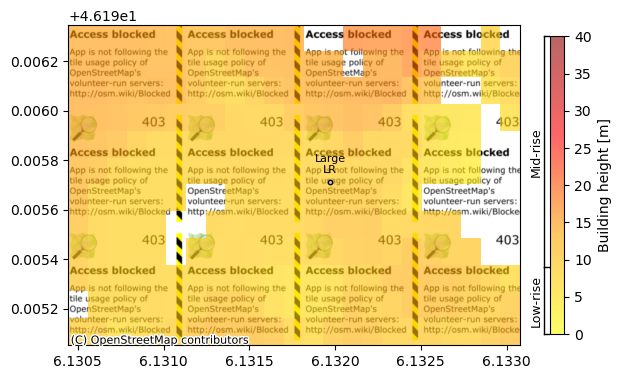

In [23]:
class_labels = {1:'Compact MR', 2:'Open MR', 3:'Open LR', 4:'Large LR',
                5:'Dense Trees', 6:'Low plants', 7:'Bare/Paved', 8:'Water'}
class_palette = {
    1: '#7A2A12', 2: '#DE6321', 3: '#EAC89E', 4: '#CFC9AE',
    5: '#5A772C', 6: '#A2C766', 7: '#4A442B', 8: '#89C9E8'
}
#!pip install contextily
import contextily as ctx

#!pip install matplotlib-scalebar
from matplotlib_scalebar.scalebar import ScaleBar


with rasterio.open(height_tiff_4326) as src:
    height_band = src.read(1, masked=True).astype(np.float32)
    height_band = height_band.filled(np.nan)
    bounds = src.bounds
    transform = src.transform

# Define area of interest

# Total
'''
location_name = 'geneva_roi'
xmin = bounds.left; xmax = bounds.right
ymin = bounds.bottom; ymax = bounds.top
'''
# Lancy gare
'''
location_name = 'lancy_gare'
xmin, xmax = 6.121700, 6.1276
ymin, ymax = 46.184042,  46.187660
'''

# Pont Butin +libellules
'''
location_name = 'butin_libel'
xmin, xmax = 6.107916, 6.111110
ymin, ymax = 46.204516,  46.206283
'''

#Pont Acacias zone
'''
location_name = 'pont_acacias'
xmin, xmax = 6.135414, 6.146743
ymin, ymax = 46.190235,  46.196283
'''

#Praille
'''
location_name = 'praille'
xmin, xmax = 6.131418, 6.134829
ymin, ymax = 46.183734,  46.185402
'''

#Meyrin x Vaudagne
'''
location_name = 'meyrin_vaudagne'
xmin, xmax = 6.071210, 6.072103
ymin, ymax = 46.228751, 46.229150
'''
#municipal
#'''
location_name = 'municipal'
xmin, xmax = 6.130446, 6.133077
ymin, ymax = 46.195053 , 46.196345
#'''


text_flag=True
if(location_name=='geneva_roi'): text_flag=False

# Convert lon/lat bounds to pixel row/col indices
row_min, col_min = rasterio.transform.rowcol(transform, xmin, ymax)  # top-left
row_max, col_max = rasterio.transform.rowcol(transform, xmax, ymin)  # bottom-right

# Clip indices to raster bounds
row_min = max(0, row_min)
row_max = min(height_band.shape[0], row_max)
col_min = max(0, col_min)
col_max = min(height_band.shape[1], col_max)

# Slice the raster to the AOI
height_crop = height_band[row_min:row_max, col_min:col_max]

# Plot
fig, ax = plt.subplots()
# 1. Add basemap FIRST


im = ax.imshow(
    height_crop,
    extent=[xmin, xmax, ymin, ymax],  # now extent matches the cropped array
    cmap=height_cmap,
    vmin=0, vmax=40,
    aspect='auto',
    alpha=0.6,
    interpolation='none',
    zorder=2
)

ctx.add_basemap(
    ax,
    crs="EPSG:4326",
    source=ctx.providers.OpenStreetMap.Mapnik,
    zorder=1
)
# Lighter basemaps:
#ctx.providers.CartoDB.Positron        # light grey, good contrast
#ctx.providers.CartoDB.DarkMatter      # dark, good for bright colormaps
#ctx.providers.Stamen.TonerLite        # minimal black and white streets
'''
cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('Building height [m]', fontsize=9)

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

ticks = [0, 9, 20, 30, 40]
labels = ["0", "9\nLow-rise", "20\nMid-rise", "30", "40"]

cbar.set_ticks(ticks)
cbar.set_ticklabels(labels)

cbar.set_label("Building height [m]", fontsize=9)
'''

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.06)
cbar.set_label("Building height [m]", fontsize=10)

axcb = cbar.ax

# Position à gauche de la colorbar
x = -0.35
tick = 0.3

# ----- Low-rise (0–9 m) -----
axcb.plot([x, x], [0, 9], color="k", lw=1, clip_on=False)
axcb.plot([x, x+tick], [0, 0], color="k", lw=1, clip_on=False)
axcb.plot([x, x+tick], [9, 9], color="k", lw=1, clip_on=False)

axcb.text(
    x-0.08, 4.5,
    "Low-rise",
    rotation=90,
    va="center",
    ha="right",
    fontsize=9
)

# ----- Mid-rise (9–40 m) -----
axcb.plot([x, x], [9, 40], color="k", lw=1, clip_on=False)
axcb.plot([x, x+tick], [40, 40], color="k", lw=1, clip_on=False)

axcb.text(
    x-0.08, 24.5,
    "Mid-rise",
    rotation=90,
    va="center",
    ha="right",
    fontsize=9
)


# Overlay train points

subset = train_centroids_gdf.cx[xmin:xmax, ymin:ymax]

if (len(subset)>0) & (text_flag==True):
    dx = (xmax-xmin)/100   # longitude
    dy = (ymax-ymin)/100   # latitude
    subset.plot(
        ax=ax,
        color=subset["LCZ_class"].map(class_palette),
        markersize=10,
        edgecolor="black",
        zorder=3
    )
    
    for _, row in subset.iterrows():
        label = class_labels[row.LCZ_class].replace(" ", "\n", 1)
        ax.text(
            row.geometry.x,
            row.geometry.y+2*dy,
            #class_labels[row.LCZ_class],
            label,
            fontsize=8,
            ha="center",
            va="bottom"
        )


# scale bar 
meters_per_degree = 111320 * np.cos(np.radians(lat_center))
scalebar = ScaleBar(
    meters_per_degree,                       
    units="m",              
    dimension="si-length",        
    #length_fraction=0.15,
    location='lower right',
    border_pad=0.5,
    box_alpha=0.7,
)
ax.add_artist(scalebar)

lat_center = (ymin + ymax) / 2
ax.set_aspect(1 / np.cos(np.radians(lat_center)))
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_xlabel('Longitude [°]', fontsize=10, loc='right')
ax.set_ylabel('Latitude [°]', fontsize=10, loc='top')

plt.savefig(out_dir + f"building_height_map_{location_name}.png", dpi=300,transparent=True, bbox_inches="tight")
plt.show()

In [ ]:
df.columns

In [ ]:
def sample_heights(fc, height_img, scale=10):
    fc_check = height_img.sampleRegions(
        collection=fc,
        properties=['LCZ_class', 'id_num'],
        scale=scale
    )
    df = pd.DataFrame(fc_check.getInfo()['features'])
    df = pd.json_normalize(df['properties'])
    return df

df_train = sample_heights(train_centroids, height)
df_test  = sample_heights(test_centroids,  height)

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

urban_classes = {1: 'Compact MR', 2: 'Open MR', 3: 'Open LR', 4: 'Large LR'}
urban_palette = {1: '#7A2A12', 2: '#DE6321', 3: '#EAC89E', 4: '#CFC9AE'}

def prep_urban(df):
    d = df[df['LCZ_class'].isin(urban_classes.keys())].copy()
    d = d.dropna(subset=['building_height'])
    d = d[d['building_height'] > 0]
    return d

def plot_height_violin(df, marker, title_suffix, out_path):
    labels = list(urban_classes.values())
    colors = list(urban_palette.values())
    data_by_class = [df[df['LCZ_class'] == cls]['building_height'].values for cls in urban_classes.keys()]
    ids_by_class   = [df[df['LCZ_class'] == cls]['id_num'].values for cls in urban_classes.keys()]

    fig, ax = plt.subplots(figsize=(9, 7))
    parts = ax.violinplot(data_by_class, positions=range(len(labels)), showmedians=True, showextrema=True)

    for pc, color in zip(parts['bodies'], colors):
        pc.set_facecolor(color); pc.set_edgecolor('black'); pc.set_alpha(0.8)
    for partname in ('cmedians', 'cmins', 'cmaxes', 'cbars'):
        parts[partname].set_edgecolor('black'); parts[partname].set_linewidth(1.2)

    for i, (data, ids, color) in enumerate(zip(data_by_class, ids_by_class, colors)):
        jitter = np.random.uniform(-0.08, 0.08, size=len(data))
        x = np.full_like(data, i, dtype=float) + jitter
        ax.scatter(x, data, marker=marker, color=color, edgecolor='black',
                   linewidth=0.5, s=40, alpha=0.75, zorder=3)
        # ID label next to each point
        for xi, yi, id_val in zip(x, data, ids):
            ax.annotate(str(int(id_val)), (xi, yi), xytext=(4, 0),
                        textcoords='offset points', fontsize=6, alpha=0.85, zorder=4)

    for i, data in enumerate(data_by_class):
        ax.text(i, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 50,
                f'n={len(data)}\nmed={np.median(data):.1f}m',
                ha='center', va='bottom', fontsize=9)

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylabel('Building height [m]', fontsize=11)
    ax.set_xlabel('LCZ class', fontsize=11)
    #ax.set_title(f'Building height distribution by urban LCZ class ({title_suffix})', fontsize=12)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    patches = [mpatches.Patch(facecolor=colors[i], edgecolor='black', label=labels[i]) for i in range(len(labels))]
    ax.legend(handles=patches, loc='best')
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()

df_train_urban = prep_urban(df_train)
df_test_urban  = prep_urban(df_test)

out_dir='./images/'
plot_height_violin(df_train_urban, marker='o', title_suffix='train',
                    out_path=out_dir + "building_height_violin_urban_lcz_train_relabelled.png")
plot_height_violin(df_test_urban,  marker='^', title_suffix='test',
                    out_path=out_dir + "building_height_violin_urban_lcz_test_relabelled.png")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

height_check = height.sampleRegions(
    collection=test_centroids,
    properties=['LCZ_class'],
    scale=10
)

df = pd.DataFrame(height_check.getInfo()['features'])
df = pd.json_normalize(df['properties'])

print(df.groupby('LCZ_class')['building_height'].describe())
print("\nHow many zeros per class:")
print(df.groupby('LCZ_class')['building_height'].apply(lambda x: (x==0).sum()))
print("\nHow many nulls per class:")
print(df.groupby('LCZ_class')['building_height'].apply(lambda x: x.isna().sum()))

# Filter to urban LCZ classes only
urban_classes = {1: 'Compact MR', 2: 'Open MR', 3: 'Open LR', 4: 'Large LR'}
urban_palette = {1: '#7A2A12', 2: '#DE6321', 3: '#EAC89E', 4: '#CFC9AE'}

df_urban = df[df['LCZ_class'].isin(urban_classes.keys())].copy()
df_urban = df_urban.dropna(subset=['building_height'])
df_urban = df_urban[df_urban['building_height'] > 0]  # exclude no-building pixels

# Prepare data per class
data_by_class = [
    df_urban[df_urban['LCZ_class'] == cls]['building_height'].values
    for cls in urban_classes.keys()
]
labels  = list(urban_classes.values())
colors  = list(urban_palette.values())

# --------------------------------------------------
# Plot
fig, ax = plt.subplots()#(figsize=(10, 6))

parts = ax.violinplot(
    data_by_class,
    positions=range(len(labels)),
    showmedians=True,
    showextrema=True,
)

# Color each violin
for i, (pc, color) in enumerate(zip(parts['bodies'], colors)):
    pc.set_facecolor(color)
    pc.set_edgecolor('black')
    pc.set_alpha(0.8)

# Style median and extrema lines
for partname in ('cmedians', 'cmins', 'cmaxes', 'cbars'):
    parts[partname].set_edgecolor('black')
    parts[partname].set_linewidth(1.2)

# Overlay individual points (jittered)
for i, (data, color) in enumerate(zip(data_by_class, colors)):
    jitter = np.random.uniform(-0.08, 0.08, size=len(data))
    ax.scatter(
        np.full_like(data, i) + jitter, data,
        color=color, edgecolor='black', linewidth=0.5,
        s=30, alpha=0.7, zorder=3
    )


# Annotations: n and median per class
for i, data in enumerate(data_by_class):
    ax.text(i, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 50,
            f'n={len(data)}\nmed={np.median(data):.1f}m',
            ha='center', va='bottom', fontsize=9)

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('Building height [m]', fontsize=11)
ax.set_xlabel('LCZ class', fontsize=11)
#ax.set_title('Building height distribution by urban LCZ class\n(train + test points)', fontsize=12)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

patches = [mpatches.Patch(facecolor=colors[i], edgecolor='black', label=labels[i])
           for i in range(len(labels))]
ax.legend(handles=patches, loc='best')

plt.tight_layout()
plt.savefig(out_dir + "building_height_violin_urban_lcz.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### **Some comparison with reference numbers**

In [ ]:
from pathlib import Path
import numpy as np

CITY_CODES = {
    "Geneva": "gen",
    "Lausanne": "lau",
    "Basel": "bas",
    "Bern": "ber",
    "Zurich": "zur",
    "Lugano": "lug",
}


def read_accuracy_file(filepath):
    with open(filepath, encoding="utf-8") as f:
        lines = f.readlines()
    print(repr(lines[64]))
    # Rows 62 and 63 (1-indexed)
    pa = np.array([float(x) for x in lines[60].strip().split(",")[1:] if x])
    ua = np.array([float(x) for x in lines[61].strip().split(",")[1:] if x])

    # Row 65
    oa = float(lines[63].split("=")[1].strip())
    
    return {
        "PA": pa,
        "UA": ua,
        "OA": oa,
    }


def load_accuracy_data(root_dir):
    data = {}

    for city, code in CITY_CODES.items():

        data[city] = {}

        for sensor in ["S2", "L8"]:
            if code=='lau':
                filepath = (Path(root_dir)/city/f"Accuracy_{code}_{sensor}_2022.csv")
            else:
                filepath = (Path(root_dir)/city/f"Accuracy_{sensor}_{code}_2022.csv")

            data[city][sensor] = read_accuracy_file(filepath)

    return data

In [ ]:
def read_accuracy_file(filepath):

    with open(filepath, encoding="utf-8") as f:
        lines = f.readlines()

    pa = None
    ua = None
    oa = None

    for line in lines:

        if line.startswith("PA [%]"):
            pa = np.array([
                float(x)
                for x in line.strip().split(",")[1:]
                if x.strip()
            ])

        elif line.startswith("UA [%]"):
            ua = np.array([
                float(x)
                for x in line.strip().split(",")[1:]
                if x.strip()
            ])

        elif "Overall accuracy" in line:
            # extract first number appearing in the line
            import re
            oa = float(re.search(r"(\d+\.\d+)", line).group(1))

    if pa is None:
        raise ValueError(f"PA row not found in {filepath}")

    if ua is None:
        raise ValueError(f"UA row not found in {filepath}")

    if oa is None:
        raise ValueError(f"OA row not found in {filepath}")

    return {
        "PA": pa,
        "UA": ua,
        "OA": oa,
    }

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

ROOT_DIR = '/home/bouchiba/notebooks/project/tables/LCZ_paper_2024/'
ref_data = load_accuracy_data(ROOT_DIR)
ref_city = test_city.capitalize()

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

x = np.arange(len(class_names))

fig, ax = plt.subplots(figsize=(7,5))

# AE embedding bars
bars = ax.bar(
    x,
    PA,
    width=0.6,
    alpha=0.7,
    color="lavender",
    label="AE embedding 2022"
)

# S2 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["S2"]["PA"],
    marker="_",
    s=400,
    linewidths=2,
    color="darkorange",
    label="S2 2022"
)

# L8 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["L8"]["PA"],
    marker="_",
    s=400,
    linewidths=2,
    color="crimson",
    label="L8 2022"
)

# Labels and title
ax.set_title(
    f"PA comparison (train:{train_city.capitalize()}, test:{test_city.capitalize()}). OA: {round(OA,2)} %",
    fontsize=12
)

ax.set_ylabel("PA (%)", fontsize=10)
ax.set_ylim(60,105)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.grid(which="major", axis="y", alpha=0.3)
ax.grid(which="minor", axis="y", alpha=0.15)

ax.set_xticks(x)
ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right",
    fontsize=8
)

ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="y", labelsize=8)

# Common y-range with padding
all_values = np.concatenate([
    PA,
    ref_data[ref_city]["S2"]["PA"],
    ref_data[ref_city]["L8"]["PA"]
])

ymin = max(0, np.min(all_values) - 5)
ymax = np.max(all_values) + 8
ax.set_ylim(ymin, ymax)

# Annotate AE values
for i, v in enumerate(PA):
    ax.text(
        i,
        v + 1,
        f"{v:.1f}",
        ha="center",
        va="bottom",
        fontsize=7
    )

# Annotate differences to references
for i, (ae, s2, l8) in enumerate(zip(
    PA,
    ref_data[ref_city]["S2"]["PA"],
    ref_data[ref_city]["L8"]["PA"]
)):
    ax.text(
        i,
        ymax - 1,
        f"S2:{ae-s2:+.1f}\nL8:{ae-l8:+.1f}",
        ha="center",
        va="top",
        fontsize=7
    )

#ax.legend(bbox_to_anchor=(1, 1), loc='upper left')

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    f"./images/comparison_PA_{train_city}_{test_city}_RF_"
    f"{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}_with_topo.png",
    dpi=600,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

ROOT_DIR = '/home/bouchiba/notebooks/project/tables/LCZ_paper_2024/'
ref_data = load_accuracy_data(ROOT_DIR)

ref_city = test_city.capitalize()

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

x = np.arange(len(class_names))

fig, ax = plt.subplots(figsize=(7,5))

# AE embedding bars
bars = ax.bar(
    x,
    UA,
    width=0.6,
    alpha=0.7,
    color="mistyrose",
    label="AE embedding 2022"
)

# S2 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["S2"]["UA"],
    marker="_",
    s=400,
    linewidths=2,
    color="darkorange",
    label="S2 2022"
)

# L8 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["L8"]["UA"],
    marker="_",
    s=400,
    linewidths=2,
    color="crimson",
    label="L8 2022"
)

# Labels and title
ax.set_title(
    f"UA comparison (train:{train_city.capitalize()}, test:{test_city.capitalize()})",
    fontsize=12
)

ax.set_ylabel("UA (%)", fontsize=10)
ax.set_ylim(60,105)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.grid(which="major", axis="y", alpha=0.3)
ax.grid(which="minor", axis="y", alpha=0.15)

ax.set_xticks(x)
ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right",
    fontsize=8
)

ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="y", labelsize=8)

# Common y-range with padding
all_values = np.concatenate([
    UA,
    ref_data[ref_city]["S2"]["UA"],
    ref_data[ref_city]["L8"]["UA"]
])

ymin = max(0, np.min(all_values) - 5)
ymax = np.max(all_values) + 8
ax.set_ylim(ymin, ymax)

# Annotate AE values
for i, v in enumerate(UA):
    ax.text(
        i,
        v + 1,
        f"{v:.1f}",
        ha="center",
        va="bottom",
        fontsize=7
    )

# Annotate differences to references
for i, (ae, s2, l8) in enumerate(zip(
    UA,
    ref_data[ref_city]["S2"]["UA"],
    ref_data[ref_city]["L8"]["UA"]
)):
    ax.text(
        i,
        ymax - 1,
        f"S2:{ae-s2:+.1f}\nL8:{ae-l8:+.1f}",
        ha="center",
        va="top",
        fontsize=7
    )

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False
)
plt.tight_layout()

plt.savefig(
    f"./images/comparison_UA_{train_city}_{test_city}_RF_"
    f"{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}_with_topo.png",
    dpi=600,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

### **Robustness tests**

#### **1) Feature importance**

In [ ]:


#!pip install seaborn
import seaborn as sns
#!pip install scipy
from scipy.stats import spearmanr

# Extract feature importances from the RF classifier

importance_dict = classifier.explain().getInfo()
importance_series = pd.Series(importance_dict['importance']).sort_values(ascending=False)

training_local = training.getInfo()
features = training_local['features']
# GEE RF importance comes out as a dict {band_name: importance}


fig, ax = plt.subplots(figsize=(12, 4))
importance_series.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Random Forest Feature Importance (64 embedding dims)')
ax.set_xlabel('Embedding dimension')
ax.set_ylabel('Importance')
ax.tick_params(axis='x', labelsize=7)
plt.tight_layout()
plt.savefig(f'./output/feature_importance_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}_with_topo.png', dpi=150)
plt.show()



In [ ]:
band_names = embeddingsImage.bandNames().getInfo()
rows = []
for f in features:
    props = f['properties']
    rows.append({b: props.get(b, np.nan) for b in band_names})

df_emb = pd.DataFrame(rows)

In [ ]:
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
import numpy as np
import matplotlib.pyplot as plt

# --- Compute Spearman correlation ---
corr_matrix, _ = spearmanr(df_emb.dropna())
corr_df = pd.DataFrame(corr_matrix, index=band_names, columns=band_names)

# --- Reorder bands via hierarchical clustering ---
# Convert correlation to distance (1 - |r| so highly correlated = close)
dist = 1 - np.abs(corr_matrix)
linkage_matrix = linkage(dist, method='ward')
order = leaves_list(linkage_matrix)  # reordered indices

corr_reordered = corr_matrix[np.ix_(order, order)]
labels_reordered = [band_names[i] for i in order]

# --- Plot with matplotlib only ---
fig, ax = plt.subplots(figsize=(10, 9))

im = ax.imshow(corr_reordered, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')

# Colorbar
cbar = fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman r')

# Ticks
ax.set_xticks(range(len(labels_reordered)))
ax.set_yticks(range(len(labels_reordered)))
ax.set_xticklabels(labels_reordered, rotation=90, fontsize=6)
ax.set_yticklabels(labels_reordered, fontsize=6)

ax.set_title('Embedding cross-correlation (hierarchically sorted)', fontsize=11)
plt.tight_layout()
plt.savefig(f'./output/embedding_correlation_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}_with_topo.png', dpi=150)
plt.show()

In [ ]:
threshold = 0.70
n_top = 12

# --- Top N bandes par importance, ordre inversé ---
top_bands = importance_series.sort_values(ascending=False).index[:n_top].tolist()
top_bands_rev = top_bands[::-1]
importance_top_rev = [importance_series[b] for b in top_bands_rev]

# Sous-matrice de corrélation depuis la matrice complète
corr_top_rev = corr_df.loc[top_bands_rev, top_bands_rev].values

tick_labels_top_rev = [f"{b}\n({imp:.3f})" for b, imp in zip(top_bands_rev, importance_top_rev)]

# Masquer le triangle inférieur (on garde le supérieur)
mask_tri = np.triu(np.ones((n_top, n_top), dtype=bool), k=1)
corr_top_masked = np.where(mask_tri, np.nan, corr_top_rev)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(corr_top_masked, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman r')

ax.set_xticks(range(n_top))
ax.set_yticks(range(n_top))
ax.set_xticklabels(tick_labels_top_rev, rotation=90, fontsize=8)
ax.set_yticklabels(tick_labels_top_rev, fontsize=8)

ax.set_xlabel('Embedding band (feature importance)', fontsize=9, loc='right')
#ax.set_ylabel('Embedding band (feature importance)', fontsize=9)

ax.invert_xaxis()

# Annoter triangle supérieur + diagonale
for i in range(n_top):
    for j in range(n_top):
        if j <= i:
            val = corr_top_rev[i, j]
            if i != j:
                ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                        fontsize=7,
                        fontweight='bold' if abs(val) > threshold else 'normal',
                        color='white' if abs(val) > 0.85 else 'black')

#ax.set_title(f'Corrélations des {n_top} bandes les plus importantes', fontsize=11)
plt.tight_layout()
plt.savefig(f'./output/embedding_correlation_top{n_top}_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}_with_topo.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import geemap

Map = geemap.Map()
Map.centerObject(roi, 12)

# Add the height layer
Map.addLayer(
    height.updateMask(height.gt(0)),  # only show where buildings exist
    {'min': 0, 'max': 40, 'palette': ['yellow', 'orange', 'red', 'darkred']},
    'Building Height'
)

# Add test and train points colored by LCZ class
Map.addLayer(test_centroids, {'color': 'blue'}, 'Test points')
Map.addLayer(train_centroids, {'color': 'green'}, 'Train points')

#Map

In [ ]:

# Defines data vs reference

ref_city = test_city.capitalize()

comparisons = [
    ("AE embedding-2022 vs S2-2022", "Δ UA (%)", UA, ref_data[ref_city]["S2"]["UA"]),
    ("AE embedding-2022 vs L8-2022", "Δ UA (%)", UA, ref_data[ref_city]["L8"]["UA"]),
    ("AE embedding-2022 vs S2-2022", "Δ PA (%)", PA, ref_data[ref_city]["S2"]["PA"]),
    ("AE embedding-2022 vs L8-2022", "Δ PA (%)", PA, ref_data[ref_city]["L8"]["PA"]),
]

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

# Compute common y-range for all subplots
max_diff = max(
    np.max(np.abs(data - ref))
    for _, _, data, ref in comparisons
)
#define pos and neg

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for ax, (title, ylabel, data, ref) in zip(axes, comparisons):

    diff = data - ref
    x = np.arange(len(class_names))

    colors = np.where(diff >= 0, "green", "red")

    ax.bar(x, diff, color=colors, alpha=0.7)

    # Reference level (difference = 0)
    ax.axhline(0, color="black", linewidth=1)

    ax.set_title(title, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=9)

    # Same y-scale for all plots + extra space for annotations
    ax.set_ylim(-max_diff * 1.15, max_diff * 1.15)

    ax.set_xticks(x)
    ax.set_xticklabels(
        class_names,
        rotation=30,
        ha="right",
        fontsize=8
    )

    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", alpha=0.3)

    # Annotate differences
    offset = max_diff * 0.05

    for i, d in enumerate(diff):
        ax.text(
            i,
            d + np.sign(d) * offset,
            f"{d:+.1f}",
            ha="center",
            va="bottom" if d >= 0 else "top",
            fontsize=7
        )

plt.tight_layout()

plt.savefig(
    f"./images/validation_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png", 
    dpi=600, transparent=True, bbox_inches='tight')

plt.show()
print(f" Saved./images/validation_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}_with_topo.png")

In [ ]:
import geemap

Map = geemap.Map()
Map.centerObject(roi, 12)

# Add the height layer
Map.addLayer(
    height.updateMask(height.gt(0)),  # only show where buildings exist
    {'min': 0, 'max': 40, 'palette': ['yellow', 'orange', 'red', 'darkred']},
    'Building Height'
)

# Add test and train points colored by LCZ class
Map.addLayer(test_centroids, {'color': 'blue'}, 'Test points')
Map.addLayer(train_centroids, {'color': 'green'}, 'Train points')

Map

### **Misclassification analysis**

#### **Misclassified points on a Map**

In [ ]:
import folium
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt


class_labels = {1:'Compact MR', 2:'Open MR', 3:'Open LR', 4:'Large LR',
                5:'Dense Trees', 6:'Low plants', 7:'Bare/Paved', 8:'Water'}

# --- Pull misclassified points locally ---
# Re-run validation with geometries=True if not done yet

misclassified = validation.filter(ee.Filter.notEquals(leftField='classification',rightField='LCZ_class'))
misclassified_local = misclassified.getInfo()  # misclassified = validation.filter(neq)

rows = []
for f in misclassified_local['features']:
    props = f['properties']
    coords = f['geometry']['coordinates']
    rows.append({
        'lon': coords[0],
        'lat': coords[1],
        'true_class':      class_labels[int(props['LCZ_class'])],
        'predicted_class': class_labels[int(props['classification'])],
        'confusion':       f"{class_labels[int(props['LCZ_class'])]} → {class_labels[int(props['classification'])]}"
    })

df_mis = pd.DataFrame(rows)

# --- Color by confusion pair ---
# Assign a color per unique confusion pair for visual grouping
unique_pairs = df_mis['confusion'].unique()
cmap = plt.cm.get_cmap('tab20', len(unique_pairs))
pair_colors = {pair: '#{:02x}{:02x}{:02x}'.format(
                    int(cmap(i)[0]*255), int(cmap(i)[1]*255), int(cmap(i)[2]*255))
               for i, pair in enumerate(unique_pairs)}

# --- Build folium map ---
center = [df_mis['lat'].mean(), df_mis['lon'].mean()]
#m = folium.Map(location=center, zoom_start=13, tiles='CartoDB positron')
m = folium.Map(location=center, zoom_start=13, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri",
    name="Satellite",
    opacity=0.7
).add_to(m)

# Optional: add the classified raster as a tile layer via GEE
# (requires geemap's get_tile_layer_url)
map_id = classified.getMapId({'min':1,'max':8,'palette':palette})


# --- Add training polygons (semi-transparent, colored by LCZ class) ---
# Use same palette as classification
class_palette = {1:'#8B0000', 2:'#FF4500', 3:'#FFA500', 4:'#FFD700',
                 5:'#228B22', 6:'#90EE90', 7:'#A9A9A9', 8:'#1E90FF'}

train_poly_layer = folium.FeatureGroup(name='Training polygons', show=True)

for _, row in train_polygons_gdf.iterrows():
    lcz = int(row['LCZ_class'])
    color = class_palette.get(lcz, '#888888')
    
    folium.GeoJson(
        row['geometry'].__geo_interface__,
        style_function=lambda f, c=color: {
            'fillColor': c,
            'color':     c,
            'weight':    1,
            'fillOpacity': 0.25,
            'opacity':     0.6
        },
        tooltip=folium.Tooltip(
            f"<b>Training polygon</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"City: {row.get('city', '?')}",
            sticky=True
        )
    ).add_to(train_poly_layer)

train_poly_layer.add_to(m)

# --- Add misclassified points with tooltips ---
for _, row in df_mis.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=6,
        color=pair_colors[row['confusion']],
        fill=True,
        fill_opacity=0.85,
        tooltip=folium.Tooltip(
            f"<b>True:</b> {row['true_class']}<br>"
            f"<b>Predicted:</b> {row['predicted_class']}",
            sticky=True
        )
    ).add_to(m)

# --- Legend for confusion pairs ---
legend_html = "<div style='position:fixed;bottom:30px;left:30px;z-index:1000;" \
              "background:white;padding:10px;border-radius:6px;font-size:12px;'>"
legend_html += "<b>Confusion pairs</b><br>"
for pair, color in pair_colors.items():
    legend_html += f"<span style='color:{color}'>●</span> {pair}<br>"
legend_html += "</div>"
m.get_root().html.add_child(folium.Element(legend_html))

folium.LayerControl().add_to(m)

# Display in notebook
from folium.plugins import Fullscreen

Fullscreen(
    position="topright",
    title="Full Screen",
    title_cancel="Exit Full Screen",
    force_separate_button=True,
).add_to(m)
m

### *Visualize classified map*

In [ ]:
import rasterio
with rasterio.open(height_tiff_path) as src:
    print("bands:", src.count)
    print("nodata:", src.nodata)
    for i in range(1, src.count + 1):
        band = src.read(i).astype(np.float32)
        print(f"band {i}: min={np.nanmin(band)}, max={np.nanmax(band)}, "
              f"nodata count={np.sum(band == -9999)}, "
              f"nan count={np.sum(np.isnan(band))}, "
              f"total pixels={band.size}")

In [ ]:

print(bounds)
print(xmin, ymin, xmax, ymax)
print(test_centroids_gdf.crs)

In [ ]:
import rasterio
import numpy as np
import pandas as pd

with rasterio.open(height_tiff_path) as src:
    height_band = src.read(3, masked=True).astype(np.float32)
    height_band = height_band.filled(np.nan)
    transform = src.transform
    tiff_crs = src.crs

# Reproject training points to match tiff CRS
train_2056 = train_centroids_gdf.to_crs(tiff_crs)

# Sample the raster at each point location
rows, cols = rasterio.transform.rowcol(
    transform,
    train_2056.geometry.x,
    train_2056.geometry.y,
)

heights = []
for r, c in zip(rows, cols):
    if 0 <= r < height_band.shape[0] and 0 <= c < height_band.shape[1]:
        heights.append(height_band[r, c])
    else:
        heights.append(np.nan)

train_export = pd.DataFrame({
    "point_id": train_centroids_gdf.index,
    "LCZ_class": train_centroids_gdf["LCZ_class"],
    "building_height": heights,
})

train_export.to_excel("./tables/training_points_building_height2.xlsx", index=False)
print(train_export.head())
print(f"\n{train_export['building_height'].isna().sum()} points had no height value")

In [ ]:
import rasterio
import numpy as np
import pandas as pd

with rasterio.open(height_tiff_path) as src:
    height_band = src.read(3, masked=True).astype(np.float32)
    height_band = height_band.filled(np.nan)
    transform = src.transform
    tiff_crs = src.crs


def sample_height_at_points(points_gdf, raster_band, raster_transform, raster_crs):
    """Reproject points to raster CRS and sample raster value at each point."""
    points_reproj = points_gdf.to_crs(raster_crs)
    rows, cols = rasterio.transform.rowcol(
        raster_transform,
        points_reproj.geometry.x,
        points_reproj.geometry.y,
    )

    heights = []
    for r, c in zip(rows, cols):
        if 0 <= r < raster_band.shape[0] and 0 <= c < raster_band.shape[1]:
            heights.append(raster_band[r, c])
        else:
            heights.append(np.nan)

    return heights


# Sample training points
train_heights = sample_height_at_points(
    train_centroids_gdf, height_band, transform, tiff_crs
)
train_export = pd.DataFrame({
    "point_id": train_centroids_gdf.index,
    "split": "train",
    "LCZ_class": train_centroids_gdf["LCZ_class"],
    "building_height": train_heights,
})

# Sample test points
test_heights = sample_height_at_points(
    test_centroids_gdf, height_band, transform, tiff_crs
)
test_export = pd.DataFrame({
    "point_id": test_centroids_gdf.index,
    "split": "test",
    "LCZ_class": test_centroids_gdf["LCZ_class"],
    "building_height": test_heights,
})

# Combine and export
combined_export = pd.concat([train_export, test_export], ignore_index=True)
combined_export.to_excel("./tables/train_test_points_building_height.xlsx", index=False)

print(combined_export.head())
print(f"\nTrain points: {len(train_export)}, missing height: {train_export['building_height'].isna().sum()}")
print(f"Test points: {len(test_export)}, missing height: {test_export['building_height'].isna().sum()}")

In [ ]:
## Export classified map 

# Convert classes -> RGB image
classified_rgb = classified.visualize(
    min=1,
    max=8,
    palette=palette
)

# Export GeoTIFF
out_dir = "./images/"
geemap.ee_export_image(
    classified_rgb.clip(roi),
    filename=out_dir+f"classified_map_RGB_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.tif",
    scale=70,
    region=roi,
    file_per_band=False
)

# Export training points/polygons
geemap.ee_to_geojson(
    train_centroids,
    filename=out_dir+'training_points_v4.geojson'
)
Map

